In [1]:

from scipy.sparse import load_npz
from pathlib import Path

import pandas as pd
import numpy as np
import re

from sklearn.cluster import DBSCAN

from sklearn.metrics import silhouette_score
from sklearn.model_selection import ParameterGrid

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.manifold import TSNE
from sklearn.metrics.pairwise import cosine_similarity

import joblib
import plotly.express as px
import matplotlib.pyplot as plt

In [2]:
processed_dir = Path("../data/processed")

matrice_tfidf = load_npz(processed_dir / "tfidf_matrix.npz")
ids = pd.read_csv(processed_dir / "tfidf_row_ids.csv")
data = pd.read_csv(processed_dir / "sample_clean.csv")

# Il faut s'assurer que la matrice TF-IDF et les identifiants des lignes correspondent
# bien aux produits du DataFrame original.
assert matrice_tfidf.shape[0] == len(ids)
assert ids["id"].is_unique
assert ids["id"].equals(data["id"])

print("Dimensions :", matrice_tfidf.shape)

Dimensions : (500, 1865)


Le cluster -1 est le cluster considéré comme du bruit par l'algorithme Dbscan. Nous allons tenter de réduire le nombre de produits dans ce cluster en ajustant les paramètres de l'algorithme.

In [3]:
# parametres = {
#     "eps": [0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0],
#     "min_samples": [2, 3, 4, 5, 6, 7, 8, 9, 10, 12, 15]
# }

# resultats = []

# for params in ParameterGrid(parametres):
#     clusters = DBSCAN(**params, metric="cosine").fit_predict(matrice_tfidf)
#     sans_bruit = clusters != -1
#     try : 
#         score = silhouette_score(
#             matrice_tfidf[sans_bruit],
#             clusters[sans_bruit],
#             metric="cosine"
#         )
#     except ValueError:
#         score = np.nan

#     resultats.append({
#         **params,
#         "silhouette": score,
#         "%_bruit": (1 - sans_bruit.mean()) * 100,
#         "nb_clusters": len(set(clusters)) - (1 if -1 in clusters else 0)
#     })

# resultats = pd.DataFrame(resultats)
# display(resultats.sort_values("nb_clusters", ascending=False))

In [4]:
parametres = {
    "eps": np.round(np.arange(0.20, 0.98, 0.01), 2),
    "min_samples": [3, 4, 5, 6, 7, 8, 9, 10, 12, 15, 20, 25, 30, 50]
}

resultats = []

for params in ParameterGrid(parametres):
    labels_test = DBSCAN(
        **params,
        metric="cosine"
    ).fit_predict(matrice_tfidf)

    sans_bruit = labels_test != -1
    tailles = pd.Series(labels_test[sans_bruit]).value_counts()
    nb_clusters = len(tailles)

    score = np.nan
    if 2 <= nb_clusters < sans_bruit.sum():
        score = silhouette_score(
            matrice_tfidf[sans_bruit],
            labels_test[sans_bruit],
            metric="cosine"
        )

    resultats.append({
        **params,
        "silhouette": score,
        "%_bruit": (~sans_bruit).mean() * 100,
        "nb_clusters": nb_clusters,
        "taille_min": tailles.min() if nb_clusters else 0,
        "%_plus_gros_cluster": (
            tailles.max() / tailles.sum() * 100
            if nb_clusters else np.nan
        )
    })

resultats = pd.DataFrame(resultats)

In [5]:
candidats = resultats[(resultats["nb_clusters"] <= 20) & (resultats["nb_clusters"] >= 10) & resultats["silhouette"].notna()]

In [6]:
display(candidats)

,eps,min_samples,silhouette,%_bruit,nb_clusters,taille_min,%_plus_gros_cluster
0,0.20,3,0.878313,90.6,13,3,17.021277
14,0.21,3,0.811767,89.8,14,3,15.686275
28,0.22,3,0.801382,89.6,14,3,15.384615
42,0.23,3,0.791471,89.4,14,3,15.094340
56,0.24,3,0.760279,89.0,14,3,14.545455
...,...,...,...,...,...,...,...
784,0.76,3,0.048366,8.8,10,4,85.087719
785,0.76,4,0.046613,9.6,12,3,84.070796
786,0.76,5,0.043955,15.2,10,5,83.962264
799,0.77,4,0.040968,7.2,11,3,85.991379


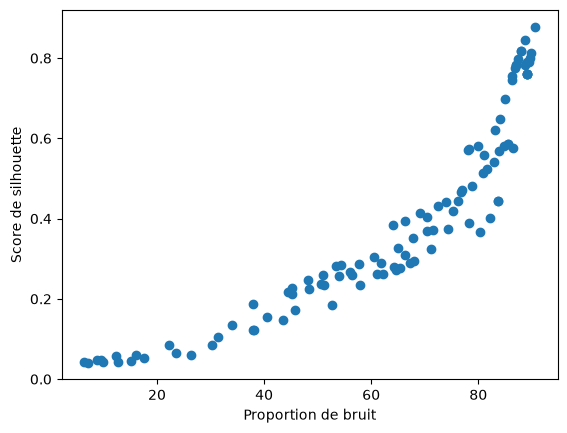

In [7]:
plt.scatter(candidats["%_bruit"], candidats["silhouette"])
plt.xlabel("Proportion de bruit")
plt.ylabel("Score de silhouette")
plt.show()

In [8]:
candidats = resultats.loc[
    resultats["nb_clusters"].between(10, 20)
    & resultats["silhouette"].notna()
].copy()

if candidats.empty:
    print("Aucun candidat dans la plage 10–20 clusters.")
    # display(resultats)
else:
    # display(candidats.sort_values(
    #     ["%_bruit", "silhouette"],
    #     ascending=[True, False]
    # ))

    fig = px.scatter(
        candidats,
        x="%_bruit",
        y="silhouette",
        color="%_plus_gros_cluster",
        hover_data=[
            "eps", "min_samples",
            "nb_clusters", "taille_min"
        ],
        title="DBSCAN — compromis entre bruit et silhouette"
    )
    fig.show()

In [9]:
meilleur = candidats.sort_values("silhouette", ascending=False).iloc[0]
display(meilleur)

eps                     0.200000
min_samples             3.000000
silhouette              0.878313
%_bruit                90.600000
nb_clusters            13.000000
taille_min              3.000000
%_plus_gros_cluster    17.021277
Name: 0, dtype: float64

In [10]:
dbscan_candidat = DBSCAN(
    eps=0.74,
    min_samples=6,
    metric="cosine"
)

labels_candidat = dbscan_candidat.fit_predict(matrice_tfidf)

lecture_candidat = ids.assign(
    cluster=labels_candidat
).merge(
    data[["id", "description_texte"]],
    on="id",
    how="left",
    validate="one_to_one"
)

tailles = lecture_candidat.loc[
    lecture_candidat["cluster"] != -1, "cluster"
].value_counts()

display(tailles.rename("nombre de produits"))

plus_gros = tailles.idxmax()
groupe = lecture_candidat.loc[
    lecture_candidat["cluster"] == plus_gros
]

display(
    groupe.sample(n=min(10, len(groupe)), random_state=42)
    [["id", "description_texte"]]
)

cluster
0     192
4      59
1      35
2       9
7       9
5       8
10      7
3       6
8       6
6       6
9       6
Name: nombre de produits, dtype: int64

,id,description_texte
109,110,relax fit organic ctn jeans - shor - everyday ...
349,350,"shop pants - long - home truck inside , shop p..."
200,201,merino 1 tank - finespun cool lower temperatur...
364,365,organic cotton boxers - day getting maytagged ...
299,300,active briefs - beating heat bali skinning fav...
479,480,borderless messenger shorts - pair lightweight...
24,25,cap 4 bottoms - sufferfests like grand january...
28,29,continental shorts - wrinkle - resistant trave...
26,27,compound cargo pants - long - ultimate - pants...
18,19,"cap 1 boxer briefs - bivy belay , form - fitti..."


# DISCUSSION NEO A ARBITRER, QUESTION METIER IMPORTANTE SUR LE CHOIX DE LA RECOMMENDATION. 